<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: E-Commerce Customer Conversion Analytics</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Ingestion and Schema Inspection (5 Marks)

Load the 'Online Shoppers Purchasing Intention' dataset directly from the UCI Machine Learning Repository (`https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv`). Once loaded into a pandas DataFrame, display the structural information of the dataset and calculate the total number of missing values for each column. Finally, use a `print()` statement to output a brief observation about the overall size and data types present in the dataset.

**Hint:** Utilize the standard pandas read function to fetch the data. The structural summary and null-counting methods will provide the necessary schema metrics.

**Expected Output:** A printed summary showing the total number of entries, the data type of each column, a tabular list indicating the count of null values per feature, and a brief written observation.

In [7]:
# Write your answer here
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"

df = pd.read_csv(url)

print(df.info())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nObservation:")
print("The dataset contains", df.shape[0], "rows and", df.shape[1], "columns.")
print("It contains both numerical and categorical variables.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

### Question 2: Missing Value and Duplicate Treatment (6 Marks)

Identify and remove any exact duplicate rows in the dataset. Following this, handle any remaining missing values by applying median imputation for numerical columns and mode imputation for categorical columns. Use a Python `print()` statement to justify why imputation was chosen over simply dropping the rows with missing values in this specific context.

**Hint:** Sequentially drop exact duplicates, then apply appropriate central tendency metrics for nulls based on data types. Use standard print output to explain your rationale.

**Expected Output:** A clean pandas DataFrame with a reduced row count, zero remaining missing values across all columns, and a printed analytical justification.

In [8]:
# Write your answer here
# Q2: Missing Value and Duplicate Treatment

# Check for duplicate rows
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

# Remove duplicate rows
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)


# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = df.select_dtypes(
    include=["object", "bool"]
).columns


# Fill missing numerical values with median
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())


# Fill missing categorical values with mode
for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])


# Check missing values after treatment
print("\nMissing values after treatment:")
print(df.isnull().sum())


# Explain why imputation is used
print("\nReason for imputation:")
print("Imputation is preferred over dropping rows because it preserves")
print("the available observations and avoids unnecessary loss of data.")

Number of duplicate rows: 125
Shape after removing duplicates: (12205, 18)

Missing values after treatment:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Reason for imputation:
Imputation is preferred over dropping rows because it preserves
the available observations and avoids unnecessary loss of data.


### Question 3: Outlier Detection and Treatment (6 Marks)

Calculate the Interquartile Range (IQR) for the `Administrative_Duration` and `ProductRelated_Duration` columns. Use this metric to cap (winsorize) the outliers at the upper bound (Q3 + 1.5 * IQR). Use a `print()` statement to explain the statistical benefit of capping extreme values rather than deleting them for this dataset.

**Hint:** Calculate the 25th (Q1) and 75th (Q3) percentiles to determine the upper bound. Reassign values exceeding this threshold to the upper bound itself. Print a brief defense of this technique.

**Expected Output:** A modified DataFrame where extreme anomalies in duration columns are contained within calculated upper bounds, accompanied by a printed explanation of the method's validity.

In [9]:
# Write your answer here

# Q3: Outlier Detection and Treatment

# Calculate Q1, Q3 and IQR for Administrative_Duration
Q1_admin = df["Administrative_Duration"].quantile(0.25)
Q3_admin = df["Administrative_Duration"].quantile(0.75)
IQR_admin = Q3_admin - Q1_admin

# Calculate upper bound
upper_admin = Q3_admin + 1.5 * IQR_admin


# Calculate Q1, Q3 and IQR for ProductRelated_Duration
Q1_product = df["ProductRelated_Duration"].quantile(0.25)
Q3_product = df["ProductRelated_Duration"].quantile(0.75)
IQR_product = Q3_product - Q1_product

# Calculate upper bound
upper_product = Q3_product + 1.5 * IQR_product


# Display the values
print("Administrative_Duration")
print("Q1:", Q1_admin)
print("Q3:", Q3_admin)
print("IQR:", IQR_admin)
print("Upper Bound:", upper_admin)

print("\nProductRelated_Duration")
print("Q1:", Q1_product)
print("Q3:", Q3_product)
print("IQR:", IQR_product)
print("Upper Bound:", upper_product)


# Cap the outliers at the upper bound
df["Administrative_Duration"] = df["Administrative_Duration"].clip(
    upper=upper_admin
)

df["ProductRelated_Duration"] = df["ProductRelated_Duration"].clip(
    upper=upper_product
)


# Observation
print("\nObservation:")
print("Outliers are capped at the upper IQR boundary instead of being deleted.")
print("This reduces the influence of extreme values while preserving all observations.")

Administrative_Duration
Q1: 0.0
Q3: 94.7
IQR: 94.7
Upper Bound: 236.75

ProductRelated_Duration
Q1: 193.0
Q3: 1477.154762
IQR: 1284.154762
Upper Bound: 3403.3869049999994

Observation:
Outliers are capped at the upper IQR boundary instead of being deleted.
This reduces the influence of extreme values while preserving all observations.


### Question 4: Correlation Analysis (7 Marks)

Assess the linear relationships among the numerical variables to identify potential multicollinearity. Generate a correlation matrix for all continuous numerical features and visualize it using an annotated heatmap. Use a `print()` statement to identify which specific pairs of variables exhibit high correlation and suggest a reason why.

**Hint:** Filter the DataFrame for numerical datatypes, compute the correlation matrix, and visualize it using a standard statistical plotting library. Print your observations regarding variable pairs.

**Expected Output:** A visual heatmap graphic displaying correlation coefficients, and a printed sentence identifying potential multicollinearity among specific features.

Correlation Matrix:
                         Administrative  Administrative_Duration  \
Administrative                 1.000000                 0.790658   
Administrative_Duration        0.790658                 1.000000   
Informational                  0.375256                 0.330261   
Informational_Duration         0.254813                 0.224007   
ProductRelated                 0.428305                 0.318419   
ProductRelated_Duration        0.399646                 0.353181   
BounceRates                   -0.213096                -0.216234   
ExitRates                     -0.311255                -0.317817   
PageValues                     0.097017                 0.102039   
SpecialDay                    -0.096951                -0.113636   
OperatingSystems              -0.006586                -0.014690   
Browser                       -0.025622                -0.030521   
Region                        -0.007262                 0.011031   
TrafficType                 

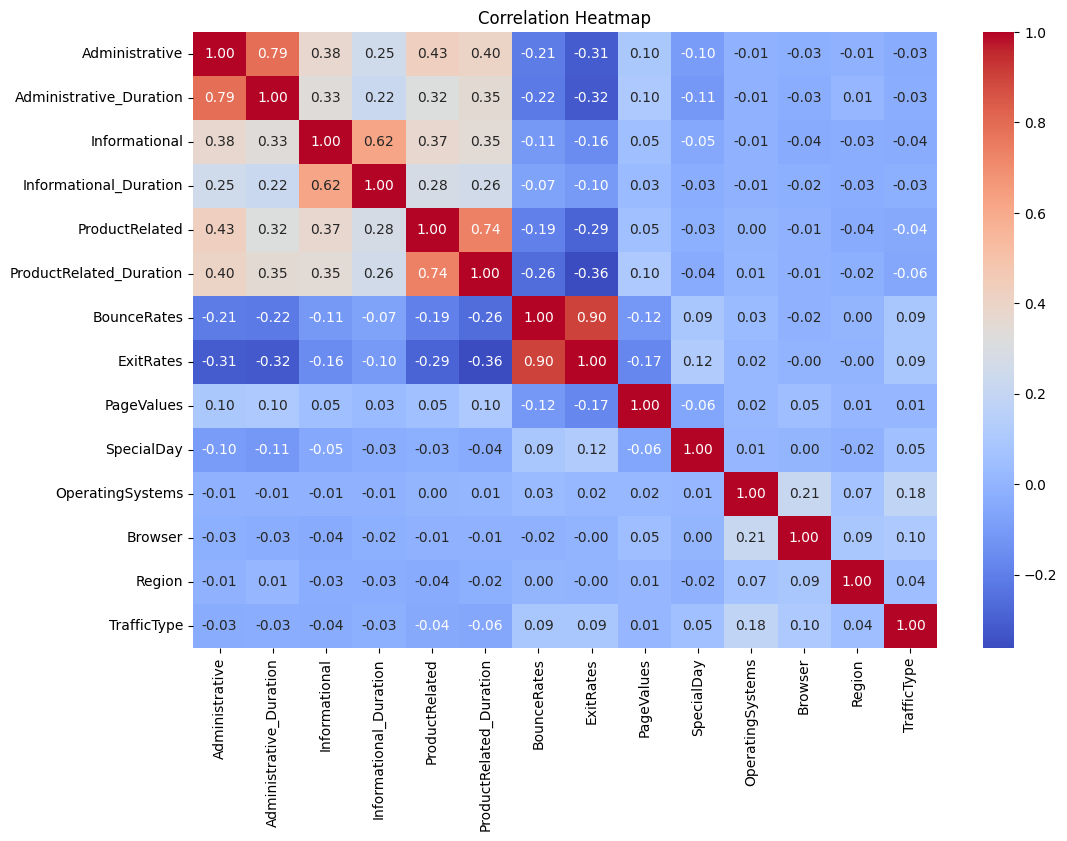


Highly correlated pairs:
Administrative and Administrative_Duration -> 0.79
ProductRelated and ProductRelated_Duration -> 0.74
BounceRates and ExitRates -> 0.9


In [10]:
# Write your answer here
# Q4: Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Select continuous numerical columns
continuous_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Calculate correlation matrix
correlation_matrix = df[continuous_columns].corr()

# Display correlation matrix
print("Correlation Matrix:")
print(correlation_matrix)


# Create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


# Find highly correlated pairs
print("\nHighly correlated pairs:")

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        correlation = correlation_matrix.iloc[i, j]

        if abs(correlation) >= 0.7:
            print(
                correlation_matrix.columns[i],
                "and",
                correlation_matrix.columns[j],
                "->",
                round(correlation, 2)
            )

### Question 5: Unsupervised Customer Segmentation (7 Marks)

Prior to supervised modeling, explore underlying patterns by applying K-Means clustering to the continuous numerical features to form 4 distinct customer segments. Append the resulting cluster labels to your DataFrame as a new categorical column named `Customer_Segment`. Use a `print()` statement to explain what behavioral patterns this unsupervised step attempts to capture.

**Hint:** Initialize the clustering algorithm with 4 clusters and a fixed random state. Apply the fit-predict method to generate labels and append them to your DataFrame. Print your analytical reasoning.

**Expected Output:** The main DataFrame updated with a new categorical column for cluster assignments, accompanied by a printed conceptual explanation.

In [11]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Exclude Revenue to avoid target leakage
features = df.select_dtypes(include="number").drop(
    columns=["Revenue"], errors="ignore"
)

# Scale features before clustering
scaler_kmeans = StandardScaler()
scaled_features = scaler_kmeans.fit_transform(features)

# Create 4 customer segments
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["Customer_Segment"] = kmeans.fit_predict(scaled_features)
df["Customer_Segment"] = df["Customer_Segment"].astype("category")

print("Customer segment counts:")
print(df["Customer_Segment"].value_counts().sort_index())

print("\nSample customer segments:")
print(df[["Customer_Segment"]].head())


Customer segment counts:
Customer_Segment
0     760
1    2979
2     922
3    7544
Name: count, dtype: int64

Sample customer segments:
  Customer_Segment
0                2
1                3
2                2
3                3
4                3


### Question 6: Categorical Encoding (6 Marks)

Convert the target variable `Revenue` into a binary integer format (1 for True, 0 for False). Apply one-hot encoding to the remaining nominal categorical features (e.g., `Month`, `VisitorType`, `Weekend`, and the newly created `Customer_Segment`).

**Hint:** Cast the boolean target to an integer type. Apply dummy variable creation with the drop-first parameter enabled to format all other textual or categorical representations.

**Expected Output:** A fully numerical DataFrame structured for modeling, containing newly generated binary columns representing the various categories of the original features.

In [12]:
# Write your answer here


import pandas as pd

# Convert Revenue to integer: True = 1, False = 0
df["Revenue"] = df["Revenue"].astype(int)

# One-hot encode categorical columns
df = pd.get_dummies(
    df,
    columns=["Month", "VisitorType", "Weekend", "Customer_Segment"],
    drop_first=True,
    dtype=int
)

# Display the encoded DataFrame
print(df.head())
print(df.dtypes)

   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay  ...  Month_May  Month_Nov  \
0         0.20       0.20         0.0         0.0  ...          0          0   
1         0.00       0.10         0.0         0.0  .

### Question 7: Feature Scaling and Data Splitting (7 Marks)

Separate the dataset into a feature matrix `X` and a target vector `y`. Split these into training and testing sets utilizing an 80/20 ratio and a random state of 42. Following the split, apply standardization to the feature matrices. You must explicitly convert the resulting scaled NumPy arrays back into Pandas DataFrames, retaining the original column names for interpretability later in the pipeline.

**Hint:** Separate target and features, then perform the split. Fit the standard scaler strictly on the training features. After transforming both sets, reconstruct them as pandas DataFrames using the original columns.

**Expected Output:** Scaled training and testing pandas DataFrames preserving column names, along with the respective target arrays.

In [13]:
# Write your answer here


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Separate features (X) and target (y)
X = df.drop("Revenue", axis=1)
y = df["Revenue"]

# 2. Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Create the scaler
scaler = StandardScaler()

# 4. Fit on training data and scale both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Convert NumPy arrays back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled, columns=X_train.columns, index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled, columns=X_test.columns, index=X_test.index
)

# 6. Display the results
print("Scaled training features:")
print(X_train_scaled.head())

print("Scaled testing features:")
print(X_test_scaled.head())

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Scaled training features:
       Administrative  Administrative_Duration  Informational  \
5304        -0.701239                -0.722207      -0.399102   
9686        -0.701239                -0.722207      -0.399102   
11085        1.398760                 1.699641       0.374233   
7515         1.398760                 2.227685      -0.399102   
6717        -0.701239                -0.722207      -0.399102   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
5304                -0.251143       -0.583839                -0.839842   
9686                -0.251143        1.228007                 0.191501   
11085                0.266853       -0.382523                -0.535723   
7515                -0.251143       -0.404891                -0.636902   
6717                -0.251143       -0.561471                 0.698575   

       BounceRates  ExitRates  PageValues  SpecialDay  ...  Month_May  \
5304     -0.450980  -0.174528   -0.320068   -0.306329  ...   1.64

### Question 8: Class Imbalance Handling (6 Marks)

Address the class imbalance in the training set using the Synthetic Minority Over-sampling Technique (SMOTE). Use a Python `print()` statement to explain why training a model on imbalanced conversion data can lead to misleading accuracy metrics.

**Hint:** Import the synthetic minority over-sampling module. Apply it exclusively to your scaled training features and training target. Print a brief explanation regarding the risks of imbalanced datasets.

**Expected Output:** Resampled training feature and target arrays that demonstrate an equal distribution of instances, plus a printed analytical statement.

In [14]:
# Write your answer here


from imblearn.over_sampling import SMOTE

# 1. Create SMOTE
smote = SMOTE(random_state=42)

# 2. Balance only the training data
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled, y_train
)

# 3. Print class counts before and after SMOTE
print("Before SMOTE:")
print(y_train.value_counts())

print("After SMOTE:")
print(y_train_resampled.value_counts())

# 4. Explain why class imbalance is a problem
print("Imbalanced conversion data can lead to misleading accuracy because a model may predict the majority class most of the time while failing to identify minority-class conversions. SMOTE balances the training classes by generating synthetic minority-class examples.")

Before SMOTE:
Revenue
0    8218
1    1546
Name: count, dtype: int64
After SMOTE:
Revenue
0    8218
1    8218
Name: count, dtype: int64
Imbalanced conversion data can lead to misleading accuracy because a model may predict the majority class most of the time while failing to identify minority-class conversions. SMOTE balances the training classes by generating synthetic minority-class examples.


### Question 9: Baseline Logistic Regression Implementation (5 Marks)

Construct a baseline Logistic Regression model. Train this model using the SMOTE-balanced training data and generate classification predictions on the unseen test set.

**Hint:** Instantiate the linear classification model, fit it to the balanced training dataset, and generate an array of predictions using the test features.

**Expected Output:** A trained standard classification model object in memory and a 1-dimensional array of binary class predictions for the test dataset.

In [15]:
# Write your answer here


from sklearn.linear_model import LogisticRegression

# 1. Create the Logistic Regression model
model = LogisticRegression(random_state=42)

# 2. Train the model using SMOTE-balanced training data
model.fit(X_train_resampled, y_train_resampled)

# 3. Predict the classes for unseen test data
y_pred = model.predict(X_test_scaled)

# 4. Display the predictions
print("Predicted classes:")
print(y_pred)

Predicted classes:
[0 1 0 ... 0 0 0]


### Question 10: Baseline Random Forest Classification (5 Marks)

Construct and train a baseline Random Forest Classifier on the balanced training data and generate test set predictions.

**Hint:** Instantiate a random forest classifier with a defined number of estimators and fixed random state. Fit the model and predict the outcomes for the test set.

**Expected Output:** A trained tree-based ensemble model object in memory and a 1-dimensional array of discrete binary predictions.

In [16]:
# Write your answer here


from sklearn.ensemble import RandomForestClassifier

# 1. Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# 2. Train the model using SMOTE-balanced training data
rf_model.fit(X_train_resampled, y_train_resampled)

# 3. Predict outcomes on the test data
y_pred_rf = rf_model.predict(X_test_scaled)

# 4. Display predictions
print("Random Forest Predictions:")
print(y_pred_rf)

Random Forest Predictions:
[0 1 0 ... 0 0 0]


### Question 11: Cross-Validation and Hyperparameter Tuning (9 Marks)

Optimize the Random Forest model architecture using an exhaustive search over specified parameter values. Configure a grid search to test combinations of `n_estimators` (e.g., 50, 100) and `max_depth` (e.g., None, 10, 20) utilizing 5-fold cross-validation.

**Hint:** Define a dictionary mapping the parameters to their search space. Pass this dictionary and the Random Forest estimator to the cross-validation search module, then execute the fit process.

**Expected Output:** An optimized model object containing the most effective combination of parameters identified during the cross-validation process.

In [17]:
# Write your answer here


from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# 1. Define the parameter values to test
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [None, 10, 20]
}

# 2. Create the Random Forest model
rf = RandomForestClassifier(random_state=42)

# 3. Set up Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# 4. Train and search for the best parameters
grid_search.fit(X_train_resampled, y_train_resampled)

# 5. Display the best parameters and optimized model
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Score:", grid_search.best_score_)
print("Optimized Model:", grid_search.best_estimator_)

Best Parameters: {'max_depth': None, 'n_estimators': 100}
Best Cross-Validation Score: 0.935146603481828
Optimized Model: RandomForestClassifier(random_state=42)


### Question 12: Metric Evaluation (ROC-AUC) (7 Marks)

Evaluate the diagnostic ability of the tuned Random Forest model using threshold-independent metrics. Calculate the ROC-AUC score and plot the corresponding Receiver Operating Characteristic (ROC) curve.

**Hint:** Compute positive class probabilities. Generate the area under the curve score and plot the true positive rate versus false positive rate.

**Expected Output:** A floating-point number representing the area under the curve, alongside a 2D line plot charting the evaluation metric.

ROC-AUC Score: 0.9263770299681902


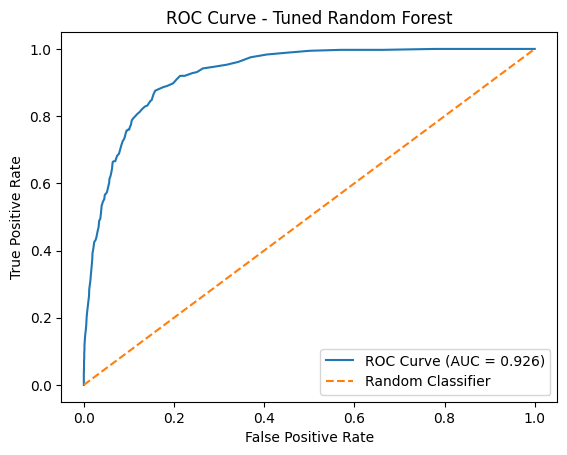

In [18]:
# Write your answer here


from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# 1. Get the tuned Random Forest model
best_model = grid_search.best_estimator_

# 2. Predict probabilities for the positive class (1)
y_prob = best_model.predict_proba(X_test_scaled)[:, 1]

# 3. Calculate ROC-AUC score
auc_score = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", auc_score)

# 4. Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# 5. Plot the ROC curve
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Random Forest")
plt.legend()
plt.show()

### Question 13: Multi-Layer Perceptron (MLP) Implementation (7 Marks)

Establish a Multi-Layer Perceptron (MLP) neural network to compare against the ensemble approach. Construct the network with two hidden layers (64 and 32 neurons respectively), utilize the ReLU activation function, and train the model on the balanced dataset. Use a Python `print()` statement to provide a brief conceptual primer on why an MLP architecture is being tested here.

**Hint:** Construct the neural network specifying the hidden layer sizes and activation function. Set a maximum iteration limit to ensure convergence. Print a sentence explaining the theoretical advantage of using an MLP to capture complex, non-linear relationships.

**Expected Output:** A converged neural network classifier object capable of predicting the binary target, and a printed conceptual primer.

In [19]:
# Write your answer here


from sklearn.neural_network import MLPClassifier

# 1. Create the MLP neural network
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    max_iter=500,
    random_state=42
)

# 2. Train the model on SMOTE-balanced training data
mlp_model.fit(X_train_resampled, y_train_resampled)

# 3. Print a conceptual explanation
print("An MLP neural network can learn complex, non-linear relationships between website visitor features and purchase conversion, making it useful for comparison with the Random Forest model.")

# 4. Display the trained model
print("Trained MLP Model:", mlp_model)

An MLP neural network can learn complex, non-linear relationships between website visitor features and purchase conversion, making it useful for comparison with the Random Forest model.
Trained MLP Model: MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)


### Question 14: Feature Importance Analysis (7 Marks)

Extract the internal feature importance scores from the tuned Random Forest model and create a horizontal bar chart of the top 10 most influential predictors. Use a `print()` statement to interpret what the highest-ranking feature suggests about customer behavior.

**Hint:** Access the importance attribute from the optimal tree model. Pair these with column names from your scaled DataFrame, sort them, and visualize using a standard plotting library. Print a brief interpretation of the top feature.

**Expected Output:** A sorted horizontal bar chart visually demonstrating influential predictors, alongside a printed analytical sentence.

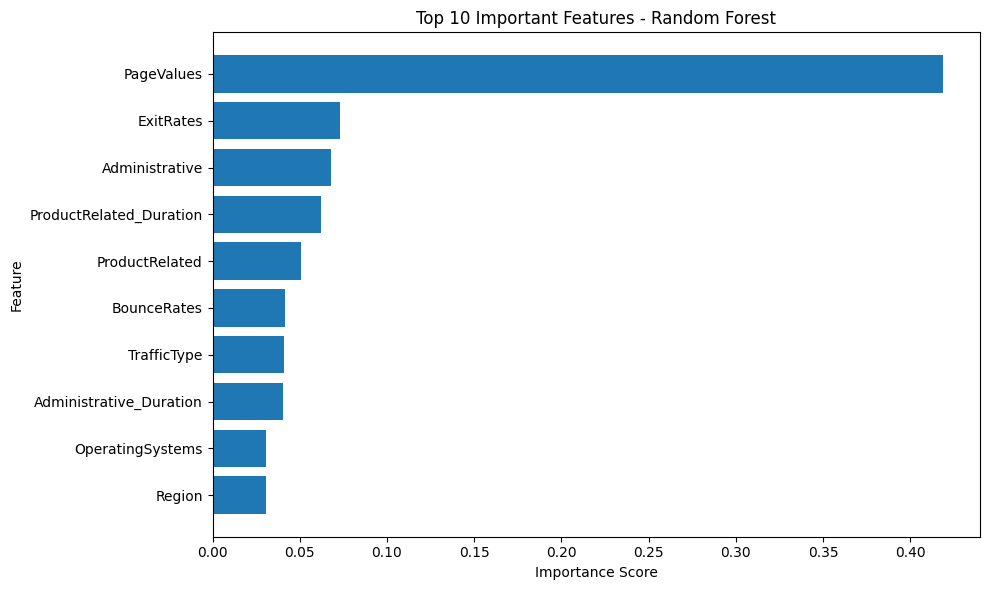

The most influential feature is PageValues. It contributes strongly to the Random Forest's predictions of customer conversion.


In [20]:
# Write your answer here


import pandas as pd
import matplotlib.pyplot as plt

# 1. Get the best Random Forest model
best_model = grid_search.best_estimator_

# 2. Extract feature importance scores
importance = best_model.feature_importances_

# 3. Create a DataFrame with feature names and importance scores
feature_importance = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Importance": importance
})

# 4. Sort features and select the top 10
top_10 = feature_importance.sort_values(
    by="Importance", ascending=False
).head(10)

# 5. Plot a horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(top_10["Feature"], top_10["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Important Features - Random Forest")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 6. Print an interpretation of the top feature
top_feature = top_10.iloc[0]["Feature"]
print(f"The most influential feature is {top_feature}. It contributes strongly to the Random Forest's predictions of customer conversion.")



### Question 15: Business Impact and Expected Value Formulation (10 Marks)

Translate model metrics into projected financial performance. Assume retaining a customer via a targeted campaign generates a net revenue of $50, while the cost of applying the campaign to any predicted positive is $10. Calculate the total expected financial impact of deploying your tuned Random Forest model on the test set. Use a Python `print()` statement to output the final monetary value and provide a brief recommendation on whether the business should deploy this model.

**Hint:** Extract True Positives (TP) and False Positives (FP) from a confusion matrix. Apply the formula where total profit equals revenue gained from true positives minus the intervention cost spent on all positive predictions. Print the calculated monetary result and your recommendation.

**Expected Output:** A calculated confusion matrix structure, and a printed monetary value representing the projected aggregate net profit, accompanied by a concluding business recommendation.

In [21]:
# Write your answer here


from sklearn.metrics import confusion_matrix

# 1. Predict using the tuned Random Forest model
best_model = grid_search.best_estimator_
y_pred_business = best_model.predict(X_test_scaled)

# 2. Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_business)
print("Confusion Matrix:")
print(cm)

# 3. Extract True Positives (TP) and False Positives (FP)
TN, FP, FN, TP = cm.ravel()

# 4. Calculate total expected net profit
revenue_per_TP = 50
cost_per_campaign = 10

total_profit = (TP * revenue_per_TP) - (
    (TP + FP) * cost_per_campaign
)

# 5. Print the financial result
print("True Positives:", TP)
print("False Positives:", FP)
print("Total Expected Net Profit:", total_profit)

# 6. Give a business recommendation
if total_profit > 0:
    print("Recommendation: Deploy the model, as it is expected to generate a positive net profit.")
elif total_profit < 0:
    print("Recommendation: Do not deploy the model in its current form, as it is expected to generate a net loss.")
else:
    print("Recommendation: The model breaks even. Further evaluation is recommended before deployment.")

Confusion Matrix:
[[1930  149]
 [ 118  244]]
True Positives: 244
False Positives: 149
Total Expected Net Profit: 8270
Recommendation: Deploy the model, as it is expected to generate a positive net profit.
